# Training YOLOv8-seg on SUN RGB-D

The one-stage baseline for the comparison: **YOLOv8s-seg**
(Ultralytics), fine-tuned from COCO weights on exactly the same splits as the
Mask R-CNN.

**Dependencies (pinned):** `ultralytics==8.4.126` — the version the std10 run was
trained with (recorded in `train/weights/best.pt`); torch / torchvision / OpenCV /
pycocotools are the ones preinstalled in Colab.

In [2]:
# install dependencies (pinned): the Ultralytics version the std10 run was trained with
!pip install -q "ultralytics==8.4.126"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.7/45.7 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 51.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 11.0 MB/s eta 0:00:00


In [3]:
from pathlib import Path
import json, time, random
import numpy as np
import pandas as pd
import cv2
import torch
import matplotlib.pyplot as plt

from pycocotools.coco import COCO
from pycocotools import mask as mask_utils
from pycocotools.cocoeval import COCOeval

from ultralytics import YOLO

from google.colab import drive
drive.mount("/content/drive")

Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart#ultralytics-settings.
Mounted at /content/drive


In [5]:
# class config to train; the archive holds the splits of all three
CONFIG = "std10"          # "std10" (10 classes) | "min400" (20) | "min100" (41)
SPLIT_SUBDIR = {"std10": "splits", "min400": "splits_min400", "min100": "splits_min100"}[CONFIG]

DRIVE_DIR = Path("/content/drive/MyDrive/Магістратура/Be be be")   # project folder on Drive
DATA_ZIP  = DRIVE_DIR / "sunrgbd_data.zip"    # archive path on Drive
DATA_ROOT = Path("/content/sunrgbd")                           # where to unpack
DATA_VERSION = "v2"       # dataset version; part of the run name, so v1 runs on Drive
                          # are never resumed by mistake
RUN_NAME  = f"{DATA_VERSION}_yolov8seg_{CONFIG}"
OUT_DIR   = DRIVE_DIR / "vkr_runs" / RUN_NAME
SPLIT_DIR = DATA_ROOT / SPLIT_SUBDIR
YOLO_ROOT = Path(f"/content/yolo_{CONFIG}")                    # converted YOLO dataset (local disk)

# unpack once per Colab session (the zip is stored uncompressed, ~5 min from Drive).
# A marker file is written only after unzip succeeds, so an interrupted or failed
# extraction (session drop, half-synced zip) is redone instead of silently reused.
import subprocess
UNPACK_OK = DATA_ROOT / ".unpacked_ok"
if not (UNPACK_OK.is_file() and UNPACK_OK.read_text() == str(DATA_ZIP.stat().st_size)):
    assert DATA_ZIP.is_file(), f"archive not found on Drive: {DATA_ZIP}"
    print("Unpacking archive...")
    DATA_ROOT.mkdir(parents=True, exist_ok=True)
    subprocess.run(["unzip", "-q", "-o", str(DATA_ZIP), "-d", str(DATA_ROOT)], check=True)
    UNPACK_OK.write_text(str(DATA_ZIP.stat().st_size))

OUT_DIR.mkdir(parents=True, exist_ok=True)
for s in ("train", "val", "test"):
    assert (SPLIT_DIR / f"instances_{s}.json").is_file(), f"missing instances_{s}.json"

# the archive must hold dataset v2 (proper polygon clipping, recovered names,
# leak-free stratified split); v1 runs live in other Drive folders
_ver = json.loads((SPLIT_DIR / "dataset_version.json").read_text())["version"]
assert _ver == DATA_VERSION, f"archive holds dataset {_ver}, expected {DATA_VERSION}: re-upload sunrgbd_data.zip"

# every image of the selected config must be on the local disk
_missing = [im["file_name"] for s in ("train", "val", "test")
            for im in json.loads((SPLIT_DIR / f"instances_{s}.json").read_text())["images"]
            if not (DATA_ROOT / im["file_name"]).is_file()]
assert not _missing, (f"{len(_missing)} images missing under {DATA_ROOT} (e.g. {_missing[0]}): "
                      f"delete {UNPACK_OK} (or restart the runtime) and rerun this cell")
print("Config:", CONFIG, "| run:", RUN_NAME)
print("Data:", DATA_ROOT)
print("Annotations:", SPLIT_DIR)
print("Outputs:", OUT_DIR)

Unpacking archive...
Config: std10 | run: v2_yolov8seg_std10
Data: /content/sunrgbd
Annotations: /content/sunrgbd/splits
Outputs: /content/drive/MyDrive/Магістратура/Be be be/vkr_runs/v2_yolov8seg_std10


In [6]:
MODEL_NAME = "yolov8s-seg.pt"   # COCO-pretrained checkpoint (auto-downloaded)
SEED       = 42
EPOCHS     = 60
BATCH_SIZE = 16
IMGSZ      = 640
PATIENCE   = 15                 # early stopping on the built-in val fitness
SCORE_THRESH_TEST = 0.05        # unified prediction protocol (02/03/04): score >= 0.05,
MAX_DETS          = 100         # at most 100 detections per image
SCORE_THRESH_VIS = 0.5          # confidence threshold for visualizations only

N_THING_CLASSES = len(json.loads(
    (SPLIT_DIR / "instances_train.json").read_text())["categories"])
print(f"{N_THING_CLASSES} thing classes (YOLO has no background class)")

10 thing classes (YOLO has no background class)


---
## Dataset conversion: COCO -> YOLO-seg

In [7]:
def _area(p):
    x, y = p[:, 0], p[:, 1]
    return abs(np.dot(x, np.roll(y, 1)) - np.dot(y, np.roll(x, 1))) / 2


def _splice(parts):
    """Splices disjoint polygons into one via zero-width bridges."""
    parts = sorted(parts, key=_area, reverse=True)
    m = parts[0]
    for c in parts[1:]:
        d2 = ((m[:, None, :] - c[None, :, :]) ** 2).sum(-1)
        i, j = np.unravel_index(np.argmin(d2), d2.shape)
        m = np.concatenate([m[:i + 1], c[j:], c[:j + 1], m[i:]])
    return m


def _poly_iou(pts, target_rle, w, h):
    flat = np.clip(pts, [0, 0], [w - 1e-3, h - 1e-3]).reshape(-1).tolist()
    rle = mask_utils.merge(mask_utils.frPyObjects([flat], h, w))
    return float(mask_utils.iou([rle], [target_rle], [0])[0][0])


def merge_polygons(polys, w, h):
    """One instance, several polygons -> one equivalent polygon (see markdown)."""
    union = mask_utils.merge(mask_utils.frPyObjects(
        [p.reshape(-1).tolist() for p in polys], h, w))
    raw = _splice(polys)
    raw_iou = _poly_iou(raw, union, w, h)
    if raw_iou >= 0.99:
        return raw
    cs, _ = cv2.findContours(mask_utils.decode(union),
                             cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    # +0.5: cv2 contour coords are pixel centers; shift to continuous space
    parts = [c.reshape(-1, 2).astype(np.float64) + 0.5 for c in cs if len(c) >= 3]
    if not parts:
        return raw
    cont = _splice(parts)
    return cont if _poly_iou(cont, union, w, h) > raw_iou else raw


if not (YOLO_ROOT / "data.yaml").is_file():
    for subset in ("train", "val", "test"):
        coco = json.loads((SPLIT_DIR / f"instances_{subset}.json").read_text())
        anns_by_img = {}
        for a in coco["annotations"]:
            anns_by_img.setdefault(a["image_id"], []).append(a)
        img_dir = YOLO_ROOT / "images" / subset
        lbl_dir = YOLO_ROOT / "labels" / subset
        img_dir.mkdir(parents=True, exist_ok=True)
        lbl_dir.mkdir(parents=True, exist_ok=True)
        n_inst = 0
        for im in coco["images"]:
            src = DATA_ROOT / im["file_name"]
            dst = img_dir / f"{im['id']}{src.suffix.lower()}"
            if not dst.exists():
                dst.symlink_to(src.resolve())
            w, h = im["width"], im["height"]
            lines = []
            for a in anns_by_img.get(im["id"], []):
                polys = [np.asarray(p, dtype=np.float64).reshape(-1, 2)
                         for p in a["segmentation"] if len(p) >= 6]
                if not polys:
                    continue
                pts = merge_polygons(polys, w, h) if len(polys) > 1 else polys[0]
                pts = np.clip(pts / [w, h], 0, 1)
                lines.append(f"{a['category_id'] - 1} " +
                             " ".join(f"{v:.6f}" for v in pts.reshape(-1)))
                n_inst += 1
            (lbl_dir / f"{im['id']}.txt").write_text("\n".join(lines) + "\n")
        print(f"{subset:<6} {len(coco['images']):>6} images, {n_inst:>7} instances")

    cats = json.loads((SPLIT_DIR / "instances_train.json").read_text())["categories"]
    yaml_txt = (f"path: {YOLO_ROOT}\ntrain: images/train\nval: images/val\n"
                f"test: images/test\nnames:\n")
    yaml_txt += "\n".join(f"  {c['id'] - 1}: {c['name']}"
                          for c in sorted(cats, key=lambda c: c["id"]))
    (YOLO_ROOT / "data.yaml").write_text(yaml_txt + "\n")

print((YOLO_ROOT / "data.yaml").read_text())

train    5983 images,   23390 instances
val      1284 images,    5050 instances
test     1287 images,    5043 instances
path: /content/yolo_std10
train: images/train
val: images/val
test: images/test
names:
  0: bed
  1: chair
  2: sofa
  3: table
  4: desk
  5: toilet
  6: dresser
  7: nightstand
  8: bookshelf
  9: bathtub



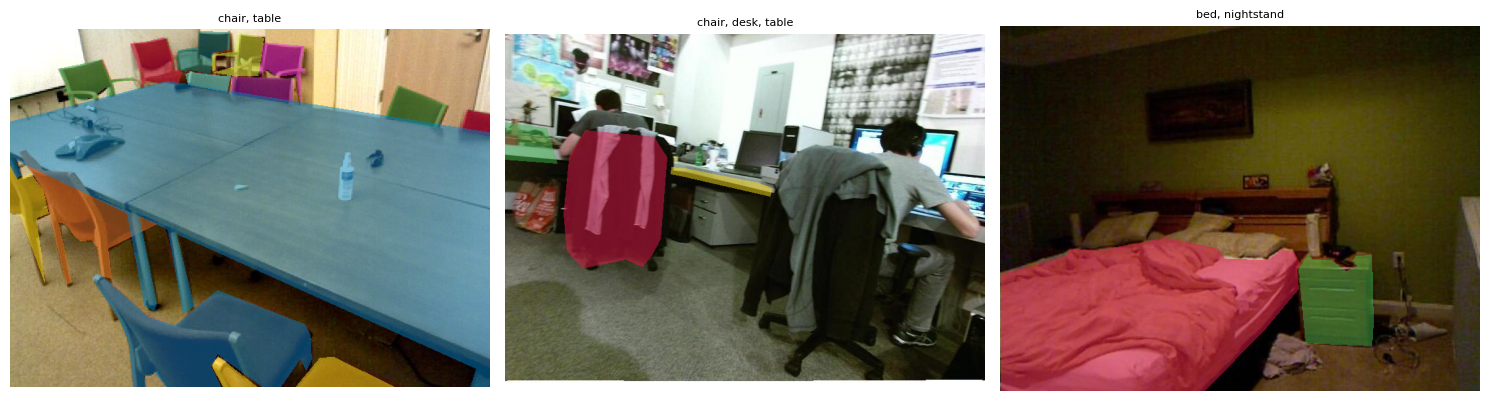

In [8]:
# visual check: rasterize a few YOLO label files back onto the images
PALETTE = np.array([
    [230,25,75],[60,180,75],[255,225,25],[0,130,200],[245,130,48],
    [145,30,180],[70,240,240],[240,50,230],[210,245,60],[0,128,128],
], dtype=np.float32) / 255.0

NAMES = {c["id"] - 1: c["name"] for c in json.loads(
    (SPLIT_DIR / "instances_train.json").read_text())["categories"]}

rng = random.Random(SEED)
label_files = rng.sample(sorted((YOLO_ROOT / "labels" / "train").glob("*.txt")), 3)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, lbl in zip(axes, label_files):
    img = cv2.imread(str(YOLO_ROOT / "images" / "train" / f"{lbl.stem}.jpg"))[:, :, ::-1]
    im = img.astype(np.float32) / 255.0
    h, w = im.shape[:2]
    classes = []
    for i, line in enumerate(l for l in lbl.read_text().split("\n") if l):
        vals = line.split()
        classes.append(NAMES[int(vals[0])])
        pts = (np.array(vals[1:], dtype=np.float64).reshape(-1, 2) * [w, h])
        m = np.zeros((h, w), np.uint8)
        cv2.fillPoly(m, [np.round(pts).astype(np.int32)], 1)
        m = m.astype(bool)
        im[m] = 0.5 * im[m] + 0.5 * PALETTE[i % len(PALETTE)]
    ax.imshow(im)
    ax.set_title(", ".join(sorted(set(classes)))[:60], fontsize=8)
    ax.axis("off")
plt.tight_layout(); plt.show()

---
## Training

Transfer learning from COCO weights with the **default Ultralytics recipe**
(SGD with warmup, cosine-free step-down, mosaic and HSV augmentations, etc.) —
the point of the comparison is each framework with its native training recipe
on identical data.

In [9]:
WEIGHTS_DIR = OUT_DIR / "train" / "weights"
last = WEIGHTS_DIR / "last.pt"

if last.is_file():
    print("Resuming from", last)
    model = YOLO(str(last))
    model.train(resume=True)
else:
    model = YOLO(MODEL_NAME)
    model.train(
        data=str(YOLO_ROOT / "data.yaml"),
        epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH_SIZE,
        seed=SEED, patience=PATIENCE, device=0,
        project=str(OUT_DIR), name="train", exist_ok=True,
        plots=True)

New https://pypi.org/project/ultralytics/8.4.175 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.126 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_std10/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train

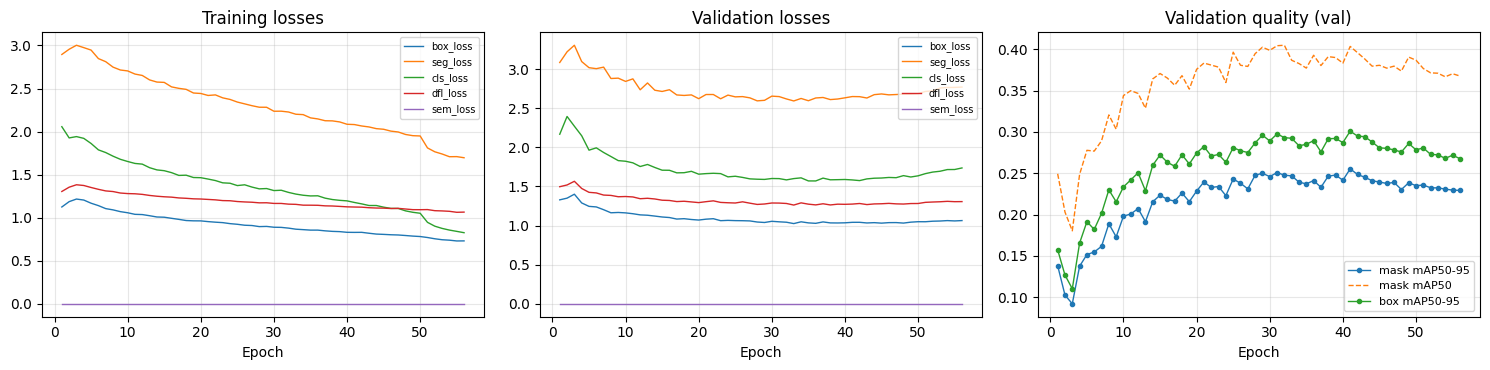

In [10]:
# training curves from results.csv — material for chapter 2
hist = pd.read_csv(OUT_DIR / "train" / "results.csv")
hist.columns = hist.columns.str.strip()

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))

for c in [c for c in hist.columns if c.startswith("train/")]:
    axes[0].plot(hist.epoch, hist[c], lw=1, label=c.replace("train/", ""))
axes[0].set_xlabel("Epoch"); axes[0].set_title("Training losses")
axes[0].legend(fontsize=7); axes[0].grid(alpha=0.3)

for c in [c for c in hist.columns if c.startswith("val/")]:
    axes[1].plot(hist.epoch, hist[c], lw=1, label=c.replace("val/", ""))
axes[1].set_xlabel("Epoch"); axes[1].set_title("Validation losses")
axes[1].legend(fontsize=7); axes[1].grid(alpha=0.3)

for col, lbl, style in [("metrics/mAP50-95(M)", "mask mAP50-95", "-o"),
                        ("metrics/mAP50(M)", "mask mAP50", "--"),
                        ("metrics/mAP50-95(B)", "box mAP50-95", "-o")]:
    if col in hist.columns:
        axes[2].plot(hist.epoch, hist[col], style, ms=3, lw=1, label=lbl)
axes[2].set_xlabel("Epoch"); axes[2].set_title("Validation quality (val)")
axes[2].legend(fontsize=8); axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(OUT_DIR / "training_curves.png", dpi=150, bbox_inches="tight")
plt.show()

---
## Final evaluation on the test set

Uses `best.pt` (the best epoch by the built-in validation fitness). The score
threshold is 0.05 like the Mask R-CNN models, not the 0.001 Ultralytics uses for
its own val mAP, so that AP is compared under identical conditions.

### Unified prediction and timing protocol (identical in notebooks 02/03/04)

* **Predictions for AP.** The model selected on validation predicts the val and
  test sets with score threshold **0.05** (torchvision `box_score_thresh`,
  Detectron2 `SCORE_THRESH_TEST`, YOLO `conf`) and at most **100** detections
  per image, in FP32; masks are binarized at 0.5 at the original image
  resolution. They are saved to `OUT_DIR/val_predictions.json` and
  `OUT_DIR/test_predictions.json` in the common COCO results format: int
  `image_id`, `category_id` = COCO category id, `bbox` = `[x, y, w, h]`,
  `segmentation` = RLE with `counts` as str, `score`. These files are the input
  of `utils/evaluate_predictions.py`, the single evaluator used to compare
  models; `test_metrics.csv` / `test_per_class_ap.csv` hold pycocotools
  COCOeval values as fractions (0–1).
* **Inference timing.** The same 100 test images for every model (the first 100
  test image ids in ascending order), decoded beforehand into RGB uint8
  H×W×3 numpy arrays in memory. The timed region is the model's own
  preprocessing + forward pass + postprocessing up to the final binary masks at
  the original resolution (score ≥ 0.05, ≤ 100 detections), FP32, batch 1;
  10 warmup runs, then 100 timed runs, with `torch.cuda.synchronize()` before
  the clock is stopped. `timing.json` stores the mean / std / median latency
  (ms) and FPS; only numbers measured on the same GPU (T4) are compared.

In [11]:
best = WEIGHTS_DIR / "best.pt"
assert best.is_file(), "best.pt not found - has training finished?"
model = YOLO(str(best))


def predict_coco(coco, chunk=16):
    """Predictions for every image of `coco` in the common COCO results format."""
    results = []
    img_ids = sorted(coco.getImgIds())
    for i in range(0, len(img_ids), chunk):
        ids = img_ids[i:i + chunk]
        paths = [str(DATA_ROOT / coco.loadImgs(j)[0]["file_name"]) for j in ids]
        outs = model.predict(paths, imgsz=IMGSZ, conf=SCORE_THRESH_TEST, max_det=MAX_DETS,
                             retina_masks=True, verbose=False, device=0)
        for img_id, out in zip(ids, outs):
            if out.masks is None:
                continue
            masks = out.masks.data.cpu().numpy() > 0.5   # [N, H, W], original resolution
            boxes = out.boxes.xyxy.cpu().numpy()
            scores = out.boxes.conf.cpu().numpy()
            classes = out.boxes.cls.cpu().numpy().astype(int)
            for m, b, s, c in zip(masks, boxes, scores, classes):
                rle = mask_utils.encode(np.asfortranarray(m.astype(np.uint8)))
                rle["counts"] = rle["counts"].decode("ascii")
                x1, y1, x2, y2 = b
                results.append({
                    "image_id": int(img_id), "category_id": int(c) + 1,
                    "bbox": [float(x1), float(y1), float(x2 - x1), float(y2 - y1)],
                    "score": float(s), "segmentation": rle,
                })
        print(f"{min(i + chunk, len(img_ids))}/{len(img_ids)}", end="\r")
    print()
    return results


# validation predictions of the selected model (the same protocol as test)
val_results = predict_coco(COCO(str(SPLIT_DIR / "instances_val.json")))
with open(OUT_DIR / "val_predictions.json", "w") as f:
    json.dump(val_results, f)
print(f"{len(val_results)} val predictions saved:", OUT_DIR / "val_predictions.json")

coco_gt = COCO(str(SPLIT_DIR / "instances_test.json"))
CLASS_NAMES = {c["id"]: c["name"] for c in coco_gt.loadCats(coco_gt.getCatIds())}

test_results = predict_coco(coco_gt)
with open(OUT_DIR / "test_predictions.json", "w") as f:
    json.dump(test_results, f)
print(f"{len(test_results)} predictions saved:", OUT_DIR / "test_predictions.json")

loading annotations into memory...
Done (t=0.05s)
creating index...
index created!
1284/1284
14058 val predictions saved: /content/drive/MyDrive/Магістратура/Be be be/vkr_runs/v2_yolov8seg_std10/val_predictions.json
loading annotations into memory...
Done (t=0.05s)
creating index...
index created!
1287/1287
13158 predictions saved: /content/drive/MyDrive/Магістратура/Be be be/vkr_runs/v2_yolov8seg_std10/test_predictions.json


In [12]:
# COCO metrics on test — the same COCOeval pipeline as notebooks 02/03
coco_dt = coco_gt.loadRes([dict(r) for r in test_results])   # loadRes adds keys in place

test_metrics, test_per_class = {}, {}
for iou_type in ("segm", "bbox"):
    ev = COCOeval(coco_gt, coco_dt, iou_type)
    ev.evaluate(); ev.accumulate(); ev.summarize()
    test_metrics[f"{iou_type}_AP"]   = ev.stats[0]
    test_metrics[f"{iou_type}_AP50"] = ev.stats[1]
    test_metrics[f"{iou_type}_AP75"] = ev.stats[2]
    test_metrics[f"{iou_type}_APs"]  = ev.stats[3]
    test_metrics[f"{iou_type}_APm"]  = ev.stats[4]
    test_metrics[f"{iou_type}_APl"]  = ev.stats[5]
    if iou_type == "segm":
        # per-class AP: precision has shape [IoU, recall, class, area, maxDet]
        prec = ev.eval["precision"]
        for k, cat_id in enumerate(ev.params.catIds):
            p = prec[:, :, k, 0, -1]
            test_per_class[CLASS_NAMES[cat_id]] = (
                float(p[p > -1].mean()) if (p > -1).any() else float("nan"))

summary = pd.DataFrame([test_metrics]).T.rename(columns={0: "value"}).round(4)
summary.to_csv(OUT_DIR / "test_metrics.csv")
print("\nFinal metrics (test):"); display(summary)

per_class_df = (pd.Series(test_per_class, name="mask AP").sort_values(ascending=False)
                .to_frame().round(4))
per_class_df.to_csv(OUT_DIR / "test_per_class_ap.csv")
print("Per-class mask AP:"); display(per_class_df)

Loading and preparing results...
DONE (t=0.01s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=2.19s).
Accumulating evaluation results...
DONE (t=0.37s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.243
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.391
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.253
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.034
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.111
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.316
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.273
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.386
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.391
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= small | maxDets=10

,value
segm_AP,0.2427
segm_AP50,0.3907
segm_AP75,0.2534
segm_APs,0.0340
segm_APm,0.1115
segm_APl,0.3155
bbox_AP,0.2847
bbox_AP50,0.3972
bbox_AP75,0.3090
bbox_APs,0.0490


Per-class mask AP:


,mask AP
toilet,0.5264
bed,0.3061
bathtub,0.2756
sofa,0.2565
table,0.2460
dresser,0.2282
chair,0.2246
nightstand,0.1614
bookshelf,0.1456
desk,0.0563


conf >= 0.5, mask IoU >= 0.5
Mean IoU of matched masks: 0.8146


,precision,recall,F1,TP,FP,FN
bed,0.7518,0.4775,0.5840,106.0,35.0,116.0
chair,0.6101,0.3553,0.4491,942.0,602.0,1709.0
sofa,0.6213,0.3231,0.4251,105.0,64.0,220.0
table,0.6832,0.3528,0.4653,399.0,185.0,732.0
desk,0.5000,0.0630,0.1119,24.0,24.0,357.0
toilet,0.7419,0.5897,0.6571,23.0,8.0,16.0
dresser,0.5179,0.2871,0.3694,29.0,27.0,72.0
nightstand,0.5000,0.1452,0.2250,9.0,9.0,53.0
bookshelf,0.5758,0.1743,0.2676,19.0,14.0,90.0
bathtub,0.8462,0.5000,0.6286,11.0,2.0,11.0


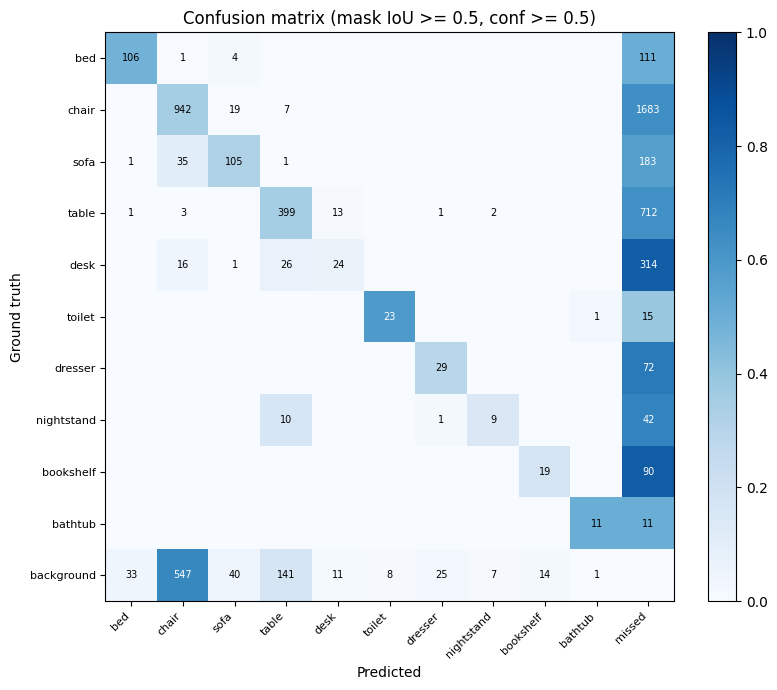

In [13]:
# extra test metrics from the saved predictions (no GPU needed):
# per-class precision / recall / F1, confusion matrix, mean IoU of matched masks
# (identical logic to notebooks 02/03 and utils/evaluate_predictions.py)
CONF_THRESH = 0.5   # confidence threshold (P/R at fixed conf, like YOLO reports)
IOU_THRESH  = 0.5   # mask IoU threshold for matching predictions to GT

preds = [p for p in test_results if p["score"] >= CONF_THRESH]

cat_ids   = sorted(coco_gt.getCatIds())
cat_names = [coco_gt.loadCats(c)[0]["name"] for c in cat_ids]
cat_idx   = {c: i for i, c in enumerate(cat_ids)}
K = len(cat_ids)

# confusion matrix: rows = GT classes (+ background), cols = predicted (+ missed)
conf = np.zeros((K + 1, K + 1), dtype=int)
tp, fp, fn = np.zeros(K, int), np.zeros(K, int), np.zeros(K, int)
matched_ious = []

preds_by_img = {}
for p in preds:
    preds_by_img.setdefault(p["image_id"], []).append(p)

for img_id in coco_gt.getImgIds():
    gts = coco_gt.loadAnns(coco_gt.getAnnIds(imgIds=img_id, iscrowd=False))
    dts = sorted(preds_by_img.get(img_id, []), key=lambda p: -p["score"])
    gt_rles = [coco_gt.annToRLE(a) for a in gts]
    dt_rles = [d["segmentation"] for d in dts]
    ious = (mask_utils.iou(dt_rles, gt_rles, [0] * len(gt_rles))
            if gt_rles and dt_rles else np.zeros((len(dt_rles), len(gt_rles))))

    # greedy class-agnostic matching by descending score
    gt_used = set()
    for di, d in enumerate(dts):
        best_gi, best_iou = -1, IOU_THRESH
        for gi in range(len(gts)):
            if gi not in gt_used and ious[di, gi] >= best_iou:
                best_gi, best_iou = gi, ious[di, gi]
        dk = cat_idx[d["category_id"]]
        if best_gi >= 0:
            gt_used.add(best_gi)
            gk = cat_idx[gts[best_gi]["category_id"]]
            conf[gk, dk] += 1
            matched_ious.append(best_iou)
            if gk == dk:
                tp[dk] += 1
            else:                     # localized but misclassified
                fp[dk] += 1; fn[gk] += 1
        else:                         # no GT match -> false positive on background
            conf[K, dk] += 1
            fp[dk] += 1
    for gi, g in enumerate(gts):      # unmatched GT -> missed object
        if gi not in gt_used:
            gk = cat_idx[g["category_id"]]
            conf[gk, K] += 1
            fn[gk] += 1

prec = tp / np.maximum(tp + fp, 1)
rec  = tp / np.maximum(tp + fn, 1)
f1   = 2 * prec * rec / np.maximum(prec + rec, 1e-9)

table = pd.DataFrame({"precision": prec, "recall": rec, "F1": f1,
                      "TP": tp, "FP": fp, "FN": fn}, index=cat_names)
mp = tp.sum() / max(tp.sum() + fp.sum(), 1)
mr = tp.sum() / max(tp.sum() + fn.sum(), 1)
table.loc["micro avg"] = [mp, mr, 2 * mp * mr / max(mp + mr, 1e-9),
                          tp.sum(), fp.sum(), fn.sum()]
table.loc["macro avg"] = [prec.mean(), rec.mean(), f1.mean(),
                          tp.sum(), fp.sum(), fn.sum()]
table = table.round(4)
table.to_csv(OUT_DIR / "test_pr_f1.csv")
print(f"conf >= {CONF_THRESH}, mask IoU >= {IOU_THRESH}")
print(f"Mean IoU of matched masks: {np.mean(matched_ious):.4f}")
display(table)

# confusion matrix normalized by GT row
norm = conf / np.maximum(conf.sum(axis=1, keepdims=True), 1)
row_lbl = cat_names + ["background"]
col_lbl = cat_names + ["missed"]
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(K + 1)); ax.set_xticklabels(col_lbl, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(K + 1)); ax.set_yticklabels(row_lbl, fontsize=8)
for i in range(K + 1):
    for j in range(K + 1):
        if conf[i, j]:
            ax.text(j, i, conf[i, j], ha="center", va="center", fontsize=7,
                    color="white" if norm[i, j] > 0.5 else "black")
ax.set_xlabel("Predicted"); ax.set_ylabel("Ground truth")
ax.set_title(f"Confusion matrix (mask IoU >= {IOU_THRESH}, conf >= {CONF_THRESH})")
fig.colorbar(im, fraction=0.046)
plt.tight_layout()
plt.savefig(OUT_DIR / "confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

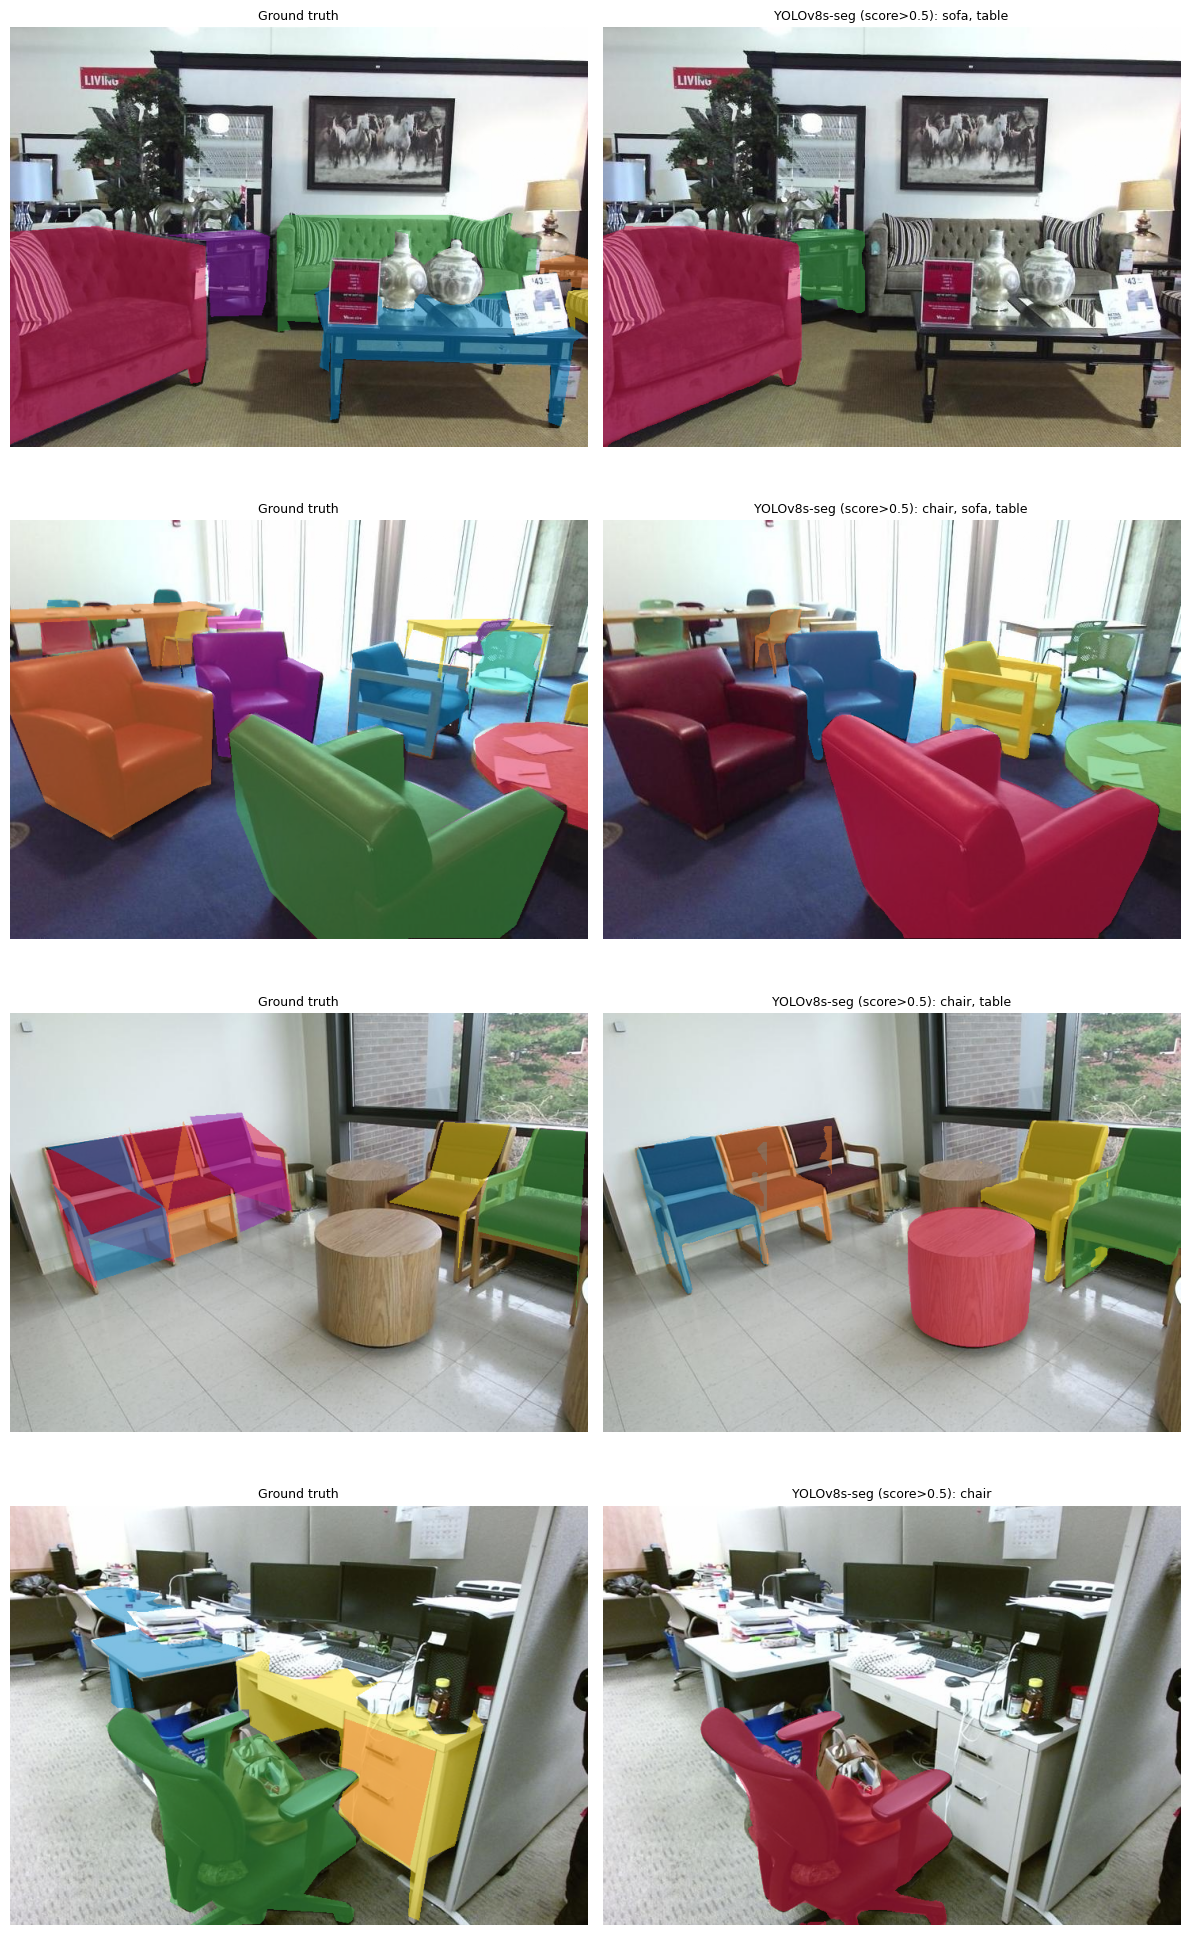

In [14]:
# qualitative examples: predictions vs ground truth (for the thesis text)
rng = random.Random(SEED)
sample_ids = rng.sample(coco_gt.getImgIds(), 4)

fig, axes = plt.subplots(len(sample_ids), 2, figsize=(12, 5 * len(sample_ids)))
for row, img_id in enumerate(sample_ids):
    info = coco_gt.loadImgs(img_id)[0]
    img_path = str(DATA_ROOT / info["file_name"])
    base = cv2.imread(img_path)[:, :, ::-1].astype(np.float32) / 255.0

    gt = base.copy()
    for i, a in enumerate(coco_gt.loadAnns(coco_gt.getAnnIds(imgIds=img_id, iscrowd=False))):
        m = coco_gt.annToMask(a).astype(bool)
        gt[m] = 0.5 * gt[m] + 0.5 * PALETTE[i % len(PALETTE)]
    axes[row, 0].imshow(gt); axes[row, 0].axis("off")
    axes[row, 0].set_title("Ground truth", fontsize=9)

    out = model.predict(img_path, imgsz=IMGSZ, conf=SCORE_THRESH_VIS,
                        retina_masks=True, verbose=False, device=0)[0]
    pred = base.copy()
    names = []
    if out.masks is not None:
        classes = out.boxes.cls.cpu().numpy().astype(int)
        for i, (m, c) in enumerate(zip(out.masks.data.cpu().numpy() > 0.5, classes)):
            pred[m] = 0.5 * pred[m] + 0.5 * PALETTE[i % len(PALETTE)]
            names.append(CLASS_NAMES[c + 1])
    axes[row, 1].imshow(pred); axes[row, 1].axis("off")
    axes[row, 1].set_title(f"YOLOv8s-seg (score>{SCORE_THRESH_VIS}): " +
                           ", ".join(sorted(set(names)))[:60], fontsize=9)

plt.tight_layout()
plt.savefig(OUT_DIR / "qualitative_test.png", dpi=150, bbox_inches="tight")
plt.show()

---
## Inference timing

End-to-end single-image latency under the unified protocol described above the
final evaluation: the same 100 test images as RGB uint8 arrays in memory,
preprocessing + forward pass + postprocessing up to the final masks at the
original resolution, score threshold 0.05, FP32, batch 1, 10 warmup + 100 timed
runs, GPU-synchronized.

In [15]:
# inference timing — the unified protocol (same cell logic in notebooks 02/03/04)
import time
import numpy as np
import torch
from PIL import Image
from pycocotools.coco import COCO

N_WARMUP, N_RUNS = 10, 100
coco_t = COCO(str(SPLIT_DIR / "instances_test.json"))
timing_ids = sorted(coco_t.getImgIds())[:N_RUNS]       # the same 100 images in 02/03/04
# decoded RGB uint8 HxWx3 arrays in memory: disk I/O and JPEG decoding are not timed
arrs = [np.array(Image.open(DATA_ROOT / coco_t.loadImgs(i)[0]["file_name"]).convert("RGB"))
        for i in timing_ids]
MODEL_TAG = f"yolov8s-seg_{CONFIG}"


def predict(rgb):
    """RGB uint8 HxWx3 -> final binary masks at the original resolution."""
    out = model.predict(np.ascontiguousarray(rgb[:, :, ::-1]),   # Ultralytics takes BGR arrays
                        imgsz=IMGSZ, conf=SCORE_THRESH_TEST, max_det=MAX_DETS,
                        retina_masks=True, verbose=False, device=0)[0]
    return None if out.masks is None else out.masks.data > 0.5


def _sync():
    if torch.cuda.is_available():
        torch.cuda.synchronize()

for a in arrs[:N_WARMUP]:
    predict(a)
_sync()
times = []
for a in arrs:
    _sync(); t0 = time.perf_counter()
    predict(a)
    _sync(); times.append(time.perf_counter() - t0)

times = np.array(times) * 1000
timing = {"model": MODEL_TAG,
          "device": (torch.cuda.get_device_name(0)
                     if torch.cuda.is_available() else "cpu"),
          "n_runs": len(times), "n_images": len(arrs),
          "score_thresh": SCORE_THRESH_TEST,
          "mean_ms": float(times.mean()), "std_ms": float(times.std()),
          "median_ms": float(np.median(times)),
          "fps": float(1000.0 / times.mean())}
(OUT_DIR / "timing.json").write_text(json.dumps(timing, indent=2))
print(json.dumps(timing, indent=2))

loading annotations into memory...
Done (t=0.10s)
creating index...
index created!
{
  "model": "yolov8s-seg_std10",
  "device": "Tesla T4",
  "n_runs": 100,
  "n_images": 100,
  "score_thresh": 0.05,
  "mean_ms": 21.710912799935613,
  "std_ms": 1.0113645277405054,
  "median_ms": 21.628274000249803,
  "fps": 46.05978611838769
}
